In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

# =============================================================================
# 1. CONFIGURATION & DATA LOADING
# =============================================================================
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 7)
data_dir = Path('../data')

try:
    df_tx = pd.read_csv(data_dir / "wban_sim_tx.csv")
    df_rx = pd.read_csv(data_dir / "wban_sim_lpu_rx.csv")
    df_hub = pd.read_csv(data_dir / "wban_sim_hub.csv")
    df_drops = pd.read_csv(data_dir / "wban_sim_drops.csv")
    df_queues = pd.read_csv(data_dir / "wban_sim_queues.csv") 
except FileNotFoundError as e:
    print(f"Error loading datasets: {e}")
    df_tx, df_rx, df_hub, df_drops, df_queues = pd.DataFrame(), pd.DataFrame(), pd.DataFrame(), pd.DataFrame(), pd.DataFrame()

# Map QoS Priorities (Updated 3-Tier Mapping)
prio_map = {0: 'CP (Priority 0)', 1: 'RP (Priority 1)', 2: 'OP (Priority 2)'}
for df in [df_tx, df_rx, df_drops, df_hub]:
    if 'Priority' in df.columns and not df.empty:
        df['QoS_Tag'] = df['Priority'].map(prio_map)

# Node Metadata Mapping
node_metadata = {
    2: {"SensorName": "EEG", "SensorType": "Streaming (P0)"},
    3: {"SensorName": "Respiration", "SensorType": "Streaming (P0)"}, 
    5: {"SensorName": "ECG", "SensorType": "Streaming (P0)"},
    10: {"SensorName": "EMG", "SensorType": "Streaming (P0)"},
    6: {"SensorName": "BloodPressure", "SensorType": "High Event (P1)"},
    7: {"SensorName": "GlucoseMonitor", "SensorType": "High Event (P1)"},
    8: {"SensorName": "SpO2", "SensorType": "High Event (P1)"},
    4: {"SensorName": "Temperature", "SensorType": "Routine (P2)"},
    9: {"SensorName": "Accelerometer", "SensorType": "Routine (P2)"},
    11: {"SensorName": "MotionSensor", "SensorType": "Routine (P2)"}
}

if not df_rx.empty:
    df_rx = df_rx.sort_values(by=['NodeID', 'Time_s'])
    df_rx['E2EDelay_us'] = df_rx['E2EDelay_s'] * 1_000_000
    df_rx['Jitter_us'] = df_rx.groupby('NodeID')['E2EDelay_us'].diff().abs()

print(f"Loaded Tx rows: {len(df_tx)}")
print(f"Loaded Rx rows: {len(df_rx)}")
print(f"Loaded Drop rows: {len(df_drops)}")
print(f"Loaded Hub rows: {len(df_hub)}")
print(f"Loaded Queue rows: {len(df_queues)}\n")

Loaded Tx rows: 2087
Loaded Rx rows: 2086
Loaded Drop rows: 0
Loaded Hub rows: 4184
Loaded Queue rows: 2000



In [12]:
# =============================================================================
# 2. STAGE-BY-STAGE METRICS & DATA RATES
# =============================================================================
print("--- STAGE-BY-STAGE NETWORK METRICS ---")

app_drops = len(df_drops[df_drops['Layer'] == 'APP']) if not df_drops.empty else 0
total_generated = len(df_tx) + app_drops
hub_rx_df = df_hub[df_hub['Event'] == 'Rx_802.15.4'] if not df_hub.empty else pd.DataFrame()

total_hub_rx = len(hub_rx_df)
total_lpu_rx = len(df_rx)

tier1_pdr = (total_hub_rx / total_generated) * 100 if total_generated > 0 else 0
tier2_pdr = (total_lpu_rx / total_hub_rx) * 100 if total_hub_rx > 0 else 0
overall_pdr = (total_lpu_rx / total_generated) * 100 if total_generated > 0 else 0

print(f"Total Packets Generated (Sensor Tx + APP Drops): {total_generated:,}")
print(f"Total Packets Reached Coordinator (Hub Rx):      {total_hub_rx:,} (Tier-1 PDR: {tier1_pdr:.2f}%)")
print(f"Total Packets Reached LPU (Final Rx):            {total_lpu_rx:,} (Tier-2 PDR: {tier2_pdr:.2f}%)")
print(f"Overall End-to-End PDR:                          {overall_pdr:.2f}%")

if not df_rx.empty:
    print(f"\nOverall Mean End-to-End Delay: {df_rx['E2EDelay_us'].mean():.2f} μs")
    print(f"Overall Mean Jitter:           {df_rx['Jitter_us'].mean():.2f} μs")
    print("\nMean Delay & Jitter by Priority:")
    display(df_rx.groupby('QoS_Tag')[['E2EDelay_us', 'Jitter_us']].mean().round(2))

sim_duration = 100.0 
if not df_rx.empty and not df_hub.empty:
    rx_bytes = df_rx['Size_bytes'].sum()
    goodput_bps = (rx_bytes * 8) / sim_duration
    
    mac_bytes = hub_rx_df['Size_bytes'].sum()
    throughput_bps = (mac_bytes * 8) / sim_duration
    
    print(f"\n--- THROUGHPUT ---")
    print(f"Tier-1 MAC Throughput (Sensors -> Hub): {throughput_bps:.2f} bps")
    print(f"Tier-2 App Goodput (Hub -> LPU): {goodput_bps:.2f} bps\n")

--- STAGE-BY-STAGE NETWORK METRICS ---
Total Packets Generated (Sensor Tx + APP Drops): 2,087
Total Packets Reached Coordinator (Hub Rx):      2,098 (Tier-1 PDR: 100.53%)
Total Packets Reached LPU (Final Rx):            2,086 (Tier-2 PDR: 99.43%)
Overall End-to-End PDR:                          99.95%

Overall Mean End-to-End Delay: 96314.90 μs
Overall Mean Jitter:           115539.80 μs

Mean Delay & Jitter by Priority:


,E2EDelay_us,Jitter_us
QoS_Tag,,
CP (Priority 0),74587.07,89095.51
OP (Priority 2),161115.03,188973.36
RP (Priority 1),72464.28,89366.64



--- THROUGHPUT ---
Tier-1 MAC Throughput (Sensors -> Hub): 11853.60 bps
Tier-2 App Goodput (Hub -> LPU): 11844.00 bps



--- TIER-1 vs TIER-2 MEAN LATENCY (μs) ---


,Tier 1 (Sensor->Coord),Tier 2 (Coord->LPU)
QoS_Tag,,
CP (Priority 0),5897.68,68693.91
OP (Priority 2),3447.10,157670.13
RP (Priority 1),6089.72,66380.79


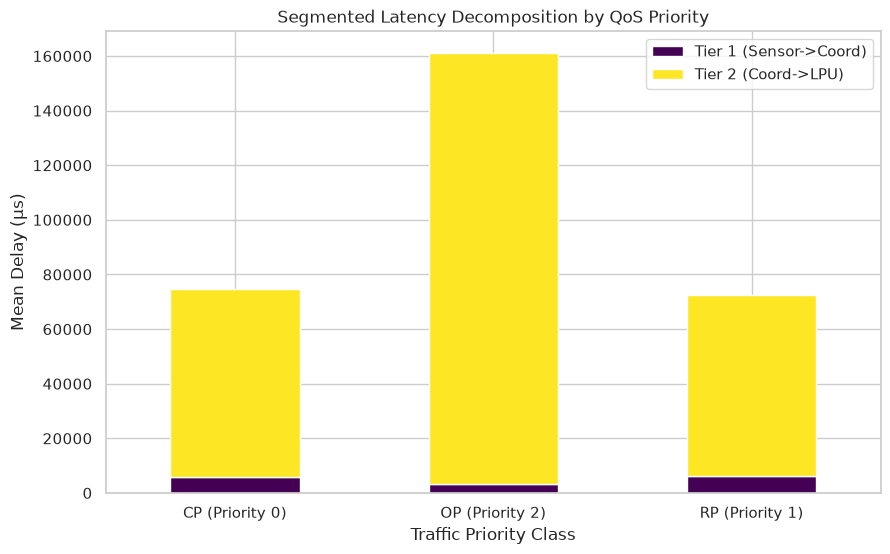

In [13]:
# =============================================================================
# 3. GRANULAR DELAY DECOMPOSITION (Microseconds)
# =============================================================================
if not df_tx.empty and not hub_rx_df.empty and not df_rx.empty:
    print("--- TIER-1 vs TIER-2 MEAN LATENCY (μs) ---")
    
    hub_rx_subset = hub_rx_df[['NodeID', 'SeqNum', 'Time_s']].rename(columns={'Time_s': 'Time_s_Hub'})
    
    df_lifecycle = df_tx.merge(hub_rx_subset, on=['NodeID', 'SeqNum'], how='inner')
    df_lifecycle = df_lifecycle.merge(df_rx[['NodeID', 'SeqNum', 'Time_s']], on=['NodeID', 'SeqNum'], suffixes=('_Tx', '_Lpu'))
    
    if not df_lifecycle.empty:
        df_lifecycle['Tier1_Delay_us'] = (df_lifecycle['Time_s_Hub'] - df_lifecycle['Time_s_Tx']) * 1_000_000
        df_lifecycle['Tier2_Delay_us'] = (df_lifecycle['Time_s_Lpu'] - df_lifecycle['Time_s_Hub']) * 1_000_000
        
        tier1_mean = df_lifecycle.groupby('QoS_Tag')['Tier1_Delay_us'].mean()
        tier2_mean = df_lifecycle.groupby('QoS_Tag')['Tier2_Delay_us'].mean()
        
        latency_summary = pd.DataFrame({'Tier 1 (Sensor->Coord)': tier1_mean, 'Tier 2 (Coord->LPU)': tier2_mean}).dropna(how='all')
        display(latency_summary.round(2))
        
        if not latency_summary.empty:
            latency_summary.plot(kind='bar', stacked=True, colormap='viridis', figsize=(10, 6))
            plt.title('Segmented Latency Decomposition by QoS Priority')
            plt.ylabel('Mean Delay (μs)')
            plt.xlabel('Traffic Priority Class')
            plt.xticks(rotation=0)
            plt.show()

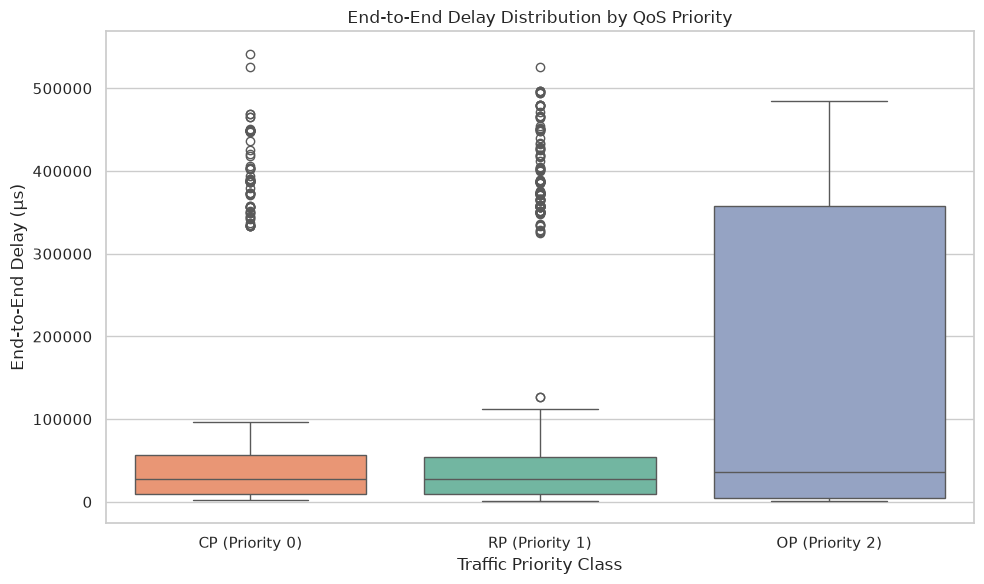

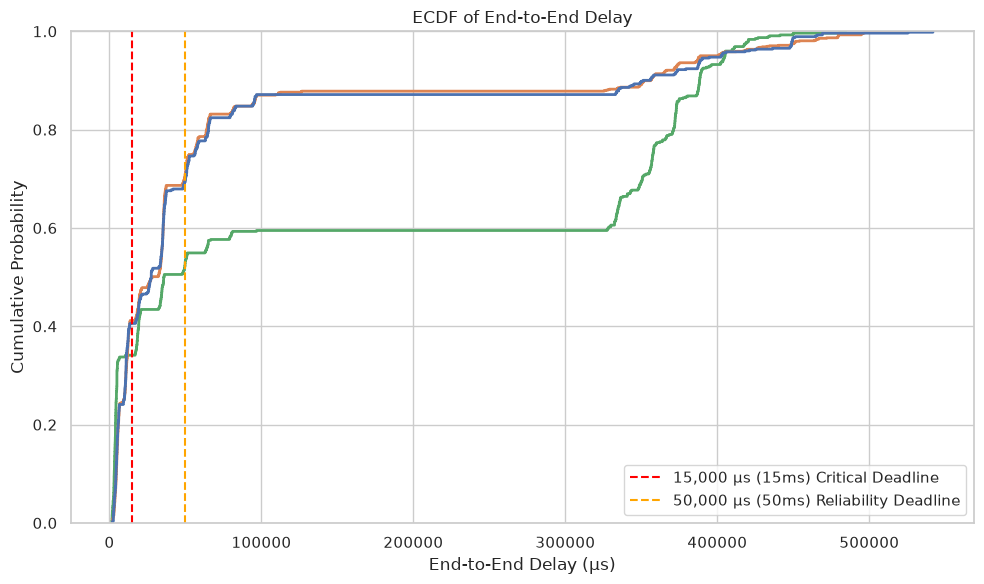

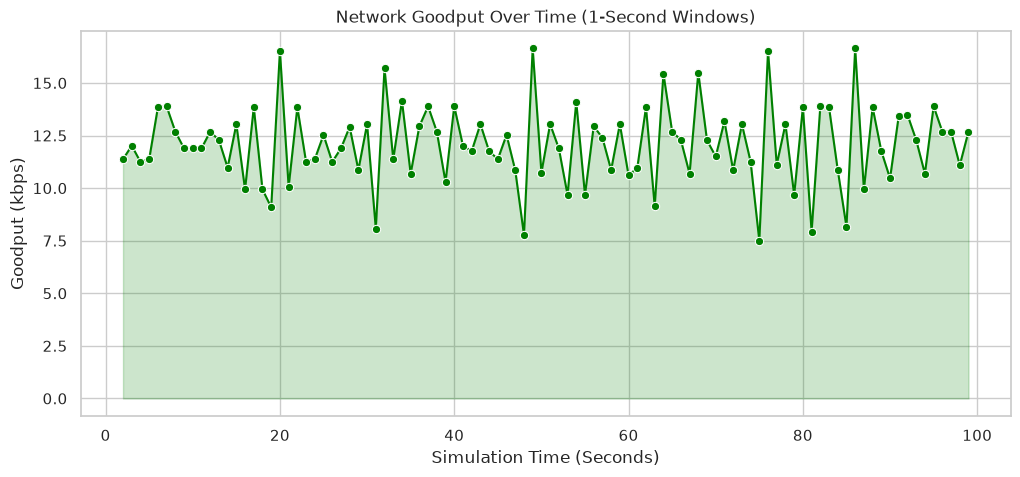

In [14]:
# =============================================================================
# 4. GLOBAL VISUALIZATIONS & DROP ANALYSIS
# =============================================================================
if not df_rx.empty:
    # A. End-to-End Delay Boxplot
    plt.figure(figsize=(10, 6))
    sns.boxplot(
        data=df_rx, x='QoS_Tag', y='E2EDelay_us', 
        hue='QoS_Tag', order=['CP (Priority 0)', 'RP (Priority 1)', 'OP (Priority 2)'], 
        palette='Set2', legend=False
    )
    plt.title('End-to-End Delay Distribution by QoS Priority')
    plt.xlabel('Traffic Priority Class')
    plt.ylabel('End-to-End Delay (μs)')
    plt.tight_layout()
    plt.show()

    # B. ECDF Tail Latency (Fixed to μs deadlines)
    plt.figure(figsize=(10, 6))
    sns.ecdfplot(
        data=df_rx, x='E2EDelay_us', hue='QoS_Tag', 
        hue_order=['CP (Priority 0)', 'RP (Priority 1)', 'OP (Priority 2)'], linewidth=2
    )
    plt.axvline(x=15_000, color='red', linestyle='--', label='15,000 μs (15ms) Critical Deadline')
    plt.axvline(x=50_000, color='orange', linestyle='--', label='50,000 μs (50ms) Reliability Deadline')
    plt.title('ECDF of End-to-End Delay')
    plt.xlabel('End-to-End Delay (μs)')
    plt.ylabel('Cumulative Probability')
    plt.legend()
    plt.tight_layout()
    plt.show()
    
    # C. Rolling Network Goodput
    df_rx['Time_Window'] = df_rx['Time_s'].astype(int)
    rolling_goodput = df_rx.groupby('Time_Window')['Size_bytes'].sum() * 8 / 1000 # kbps
    if not rolling_goodput.empty:
        plt.figure(figsize=(12, 5))
        sns.lineplot(x=rolling_goodput.index, y=rolling_goodput.values, color='green', marker='o')
        plt.title('Network Goodput Over Time (1-Second Windows)')
        plt.xlabel('Simulation Time (Seconds)')
        plt.ylabel('Goodput (kbps)')
        plt.fill_between(rolling_goodput.index, rolling_goodput.values, alpha=0.2, color='green')
        plt.show()

--- 1. OVERALL PACKET GENERATION RATIOS (SYSTEM-WIDE) ---


,QoS_Tag,Count,Ratio_%
0,RP (Priority 1),987,47.29
1,CP (Priority 0),552,26.45
2,OP (Priority 2),548,26.26



--- 2. PACKET GENERATION BY SENSOR TYPE (HIERARCHY) ---


QoS_Tag,CP (Priority 0),OP (Priority 2),RP (Priority 1),Total,CP_%,RP_%,OP_%
SensorType,,,,,,,
High Event (P1),48,148,95,291,16.49,32.65,50.86
Routine (P2),88,380,128,596,14.77,21.48,63.76
Streaming (P0),416,20,764,1200,34.67,63.67,1.67



--- 3. PACKET GENERATION PER INDIVIDUAL SENSOR ---


QoS_Tag,CP (Priority 0),OP (Priority 2),RP (Priority 1),Total,CP_%,RP_%,OP_%
SensorName,,,,,,,
Accelerometer,33,125,41,199,16.58,20.60,62.81
BloodPressure,17,47,32,96,17.71,33.33,48.96
ECG,136,4,260,400,34.00,65.00,1.00
EEG,132,6,262,400,33.00,65.50,1.50
EMG,64,5,131,200,32.00,65.50,2.50
GlucoseMonitor,12,56,29,97,12.37,29.90,57.73
MotionSensor,28,123,47,198,14.14,23.74,62.12
Respiration,84,5,111,200,42.00,55.50,2.50
SpO2,19,45,34,98,19.39,34.69,45.92


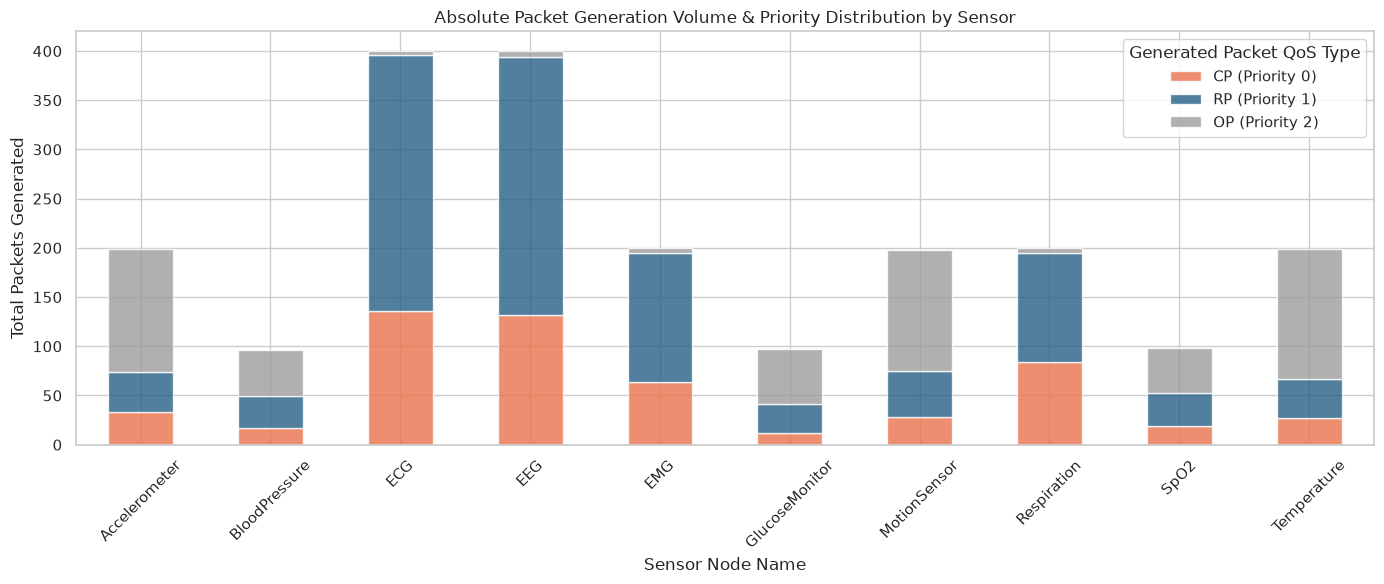

In [15]:
# =============================================================================
# 5. PACKET GENERATION STATISTICS (Overall, By Type, By Sensor)
# =============================================================================
if not df_tx.empty:
    df_tx['SensorName'] = df_tx['NodeID'].map(lambda x: node_metadata.get(x, {}).get('SensorName', 'Unknown'))
    df_tx['SensorType'] = df_tx['NodeID'].map(lambda x: node_metadata.get(x, {}).get('SensorType', 'Unknown'))
    
    print("--- 1. OVERALL PACKET GENERATION RATIOS (SYSTEM-WIDE) ---")
    overall_counts = df_tx['QoS_Tag'].value_counts().reset_index()
    overall_counts.columns = ['QoS_Tag', 'Count']
    overall_counts['Ratio_%'] = (overall_counts['Count'] / overall_counts['Count'].sum()) * 100
    display(overall_counts.round(2))
    
    print("\n--- 2. PACKET GENERATION BY SENSOR TYPE (HIERARCHY) ---")
    type_counts = df_tx.groupby(['SensorType', 'QoS_Tag']).size().unstack(fill_value=0)
    type_counts['Total'] = type_counts.sum(axis=1)
    for col in ['CP (Priority 0)', 'RP (Priority 1)', 'OP (Priority 2)']:
        if col in type_counts.columns:
            type_counts[f'{col[:2]}_%'] = (type_counts[col] / type_counts['Total']) * 100
    display(type_counts.round(2))
    
    print("\n--- 3. PACKET GENERATION PER INDIVIDUAL SENSOR ---")
    sensor_counts = df_tx.groupby(['SensorName', 'QoS_Tag']).size().unstack(fill_value=0)
    sensor_counts['Total'] = sensor_counts.sum(axis=1)
    for col in ['CP (Priority 0)', 'RP (Priority 1)', 'OP (Priority 2)']:
        if col in sensor_counts.columns:
            sensor_counts[f'{col[:2]}_%'] = (sensor_counts[col] / sensor_counts['Total']) * 100
    display(sensor_counts.round(2))
    
    # Absolute Stacked Bar Chart
    fig, ax = plt.subplots(figsize=(14, 6))
    plot_data = sensor_counts[[c for c in ['CP (Priority 0)', 'RP (Priority 1)', 'OP (Priority 2)'] if c in sensor_counts.columns]]
    plot_data.plot(kind='bar', stacked=True, ax=ax, color=['#E9724C', '#255F85', '#9C9C9C'], alpha=0.8)
    ax.set_title('Absolute Packet Generation Volume & Priority Distribution by Sensor')
    ax.set_xlabel('Sensor Node Name')
    ax.set_ylabel('Total Packets Generated')
    ax.tick_params(axis='x', rotation=45)
    plt.legend(title='Generated Packet QoS Type')
    plt.tight_layout()
    plt.show()

--- PER-NODE STAGE TRACKING & PERFORMANCE ---


,NodeID,SensorName,SensorType,Total_Generated,Tx_Sensor,Rx_Coordinator,Rx_LPU,App_Drops,Mac_Drops,Overall_PDR_%,E2EDelay_us,Jitter_us
0,0,Unknown,Unknown,0.0,0.0,1,0.0,0,0,NaN,NaN,NaN
1,2,EEG,Streaming (P0),400.0,400.0,400,400.0,0,0,100.00,34141.05,31908.99
2,3,Respiration,Streaming (P0),200.0,200.0,200,200.0,0,0,100.00,42629.73,58566.59
3,4,Temperature,Routine (P2),199.0,199.0,199,199.0,0,0,100.00,213742.44,227797.75
4,5,ECG,Streaming (P0),400.0,400.0,400,400.0,0,0,100.00,47843.54,41850.75
5,6,BloodPressure,High Event (P1),96.0,96.0,96,96.0,0,0,100.00,61469.22,85718.15
6,7,GlucoseMonitor,High Event (P1),97.0,97.0,97,97.0,0,0,100.00,80540.68,127489.68
7,8,SpO2,High Event (P1),98.0,98.0,98,98.0,0,0,100.00,110629.34,189187.97
8,9,Accelerometer,Routine (P2),199.0,199.0,199,199.0,0,0,100.00,190369.74,225879.57
9,10,EMG,Streaming (P0),200.0,200.0,200,200.0,0,0,100.00,90959.46,137200.01


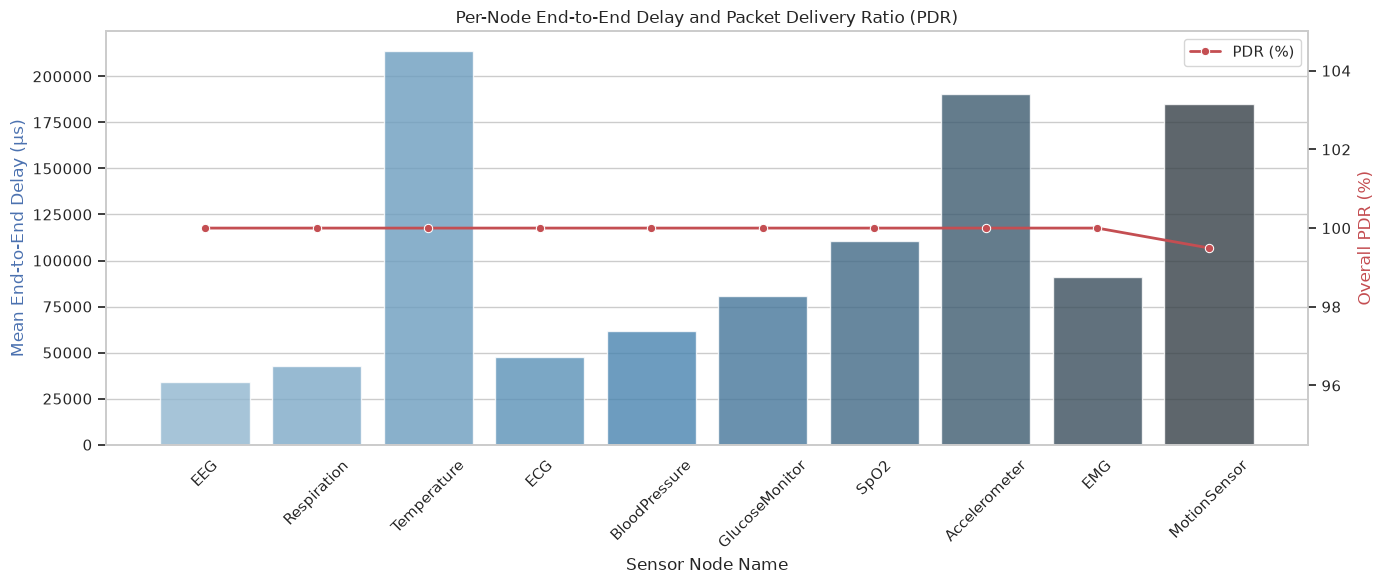

In [16]:
# =============================================================================
# 6. PER-NODE PERFORMANCE AGGREGATION & PDR VISUALIZATION
# =============================================================================
if not df_tx.empty:
    tx_node = df_tx.groupby('NodeID').size().reset_index(name='Tx_Sensor')
    
    # Isolate uniquely received packets at the coordinator layer
    hub_unique = df_hub.drop_duplicates(subset=['NodeID', 'SeqNum']) if not df_hub.empty else pd.DataFrame(columns=['NodeID', 'SeqNum'])
    hub_node = hub_unique.groupby('NodeID').size().reset_index(name='Rx_Coordinator')
    
    lpu_node = df_rx.groupby('NodeID').size().reset_index(name='Rx_LPU') if not df_rx.empty else pd.DataFrame(columns=['NodeID', 'Rx_LPU'])
    
    node_perf = pd.merge(tx_node, hub_node, on='NodeID', how='outer')
    node_perf = pd.merge(node_perf, lpu_node, on='NodeID', how='outer').fillna(0)

    if not df_drops.empty:
        app_drops_node = df_drops[df_drops['Layer'] == 'APP'].groupby('NodeID').size().reset_index(name='App_Drops')
        mac_drops_node = df_drops[df_drops['Layer'] == 'MAC'].groupby('NodeID').size().reset_index(name='Mac_Drops')
        node_perf = pd.merge(node_perf, app_drops_node, on='NodeID', how='left')
        node_perf = pd.merge(node_perf, mac_drops_node, on='NodeID', how='left').fillna(0)
    else:
        node_perf['App_Drops'], node_perf['Mac_Drops'] = 0, 0

    node_perf['Total_Generated'] = node_perf['Tx_Sensor'] + node_perf['App_Drops']
    node_perf['Overall_PDR_%'] = (node_perf['Rx_LPU'] / node_perf['Total_Generated'].replace(0, np.nan)) * 100

    if not df_rx.empty:
        mean_metrics = df_rx.groupby('NodeID')[['E2EDelay_us', 'Jitter_us']].mean().reset_index()
        node_perf = pd.merge(node_perf, mean_metrics, on='NodeID', how='left')
    else:
        node_perf['E2EDelay_us'], node_perf['Jitter_us'] = np.nan, np.nan

    node_perf['SensorName'] = node_perf['NodeID'].map(lambda x: node_metadata.get(x, {}).get('SensorName', 'Unknown'))
    node_perf['SensorType'] = node_perf['NodeID'].map(lambda x: node_metadata.get(x, {}).get('SensorType', 'Unknown'))

    cols = ['NodeID', 'SensorName', 'SensorType', 'Total_Generated', 'Tx_Sensor', 'Rx_Coordinator', 'Rx_LPU', 
            'App_Drops', 'Mac_Drops', 'Overall_PDR_%', 'E2EDelay_us', 'Jitter_us']
    
    node_perf = node_perf[[c for c in cols if c in node_perf.columns]].sort_values(by='NodeID').reset_index(drop=True)

    print("--- PER-NODE STAGE TRACKING & PERFORMANCE ---")
    display(node_perf.round(2))

    # Visualization
    if not node_perf['E2EDelay_us'].isna().all():
        fig, ax1 = plt.subplots(figsize=(14, 6))

        sns.barplot(data=node_perf, x='SensorName', y='E2EDelay_us', ax=ax1, palette='Blues_d', alpha=0.8, hue='SensorName', legend=False)
        ax1.set_title('Per-Node End-to-End Delay and Packet Delivery Ratio (PDR)')
        ax1.set_xlabel('Sensor Node Name')
        ax1.set_ylabel('Mean End-to-End Delay (μs)', color='b')
        ax1.tick_params(axis='x', rotation=45)

        ax2 = ax1.twinx()
        sns.lineplot(data=node_perf, x='SensorName', y='Overall_PDR_%', ax=ax2, color='r', marker='o', linewidth=2, label='PDR (%)')
        ax2.set_ylabel('Overall PDR (%)', color='r')

        min_pdr = node_perf['Overall_PDR_%'].min()
        ax2.set_ylim(max(0, min_pdr - 5), 105) 
        ax2.grid(False)

        plt.tight_layout()
        plt.show()

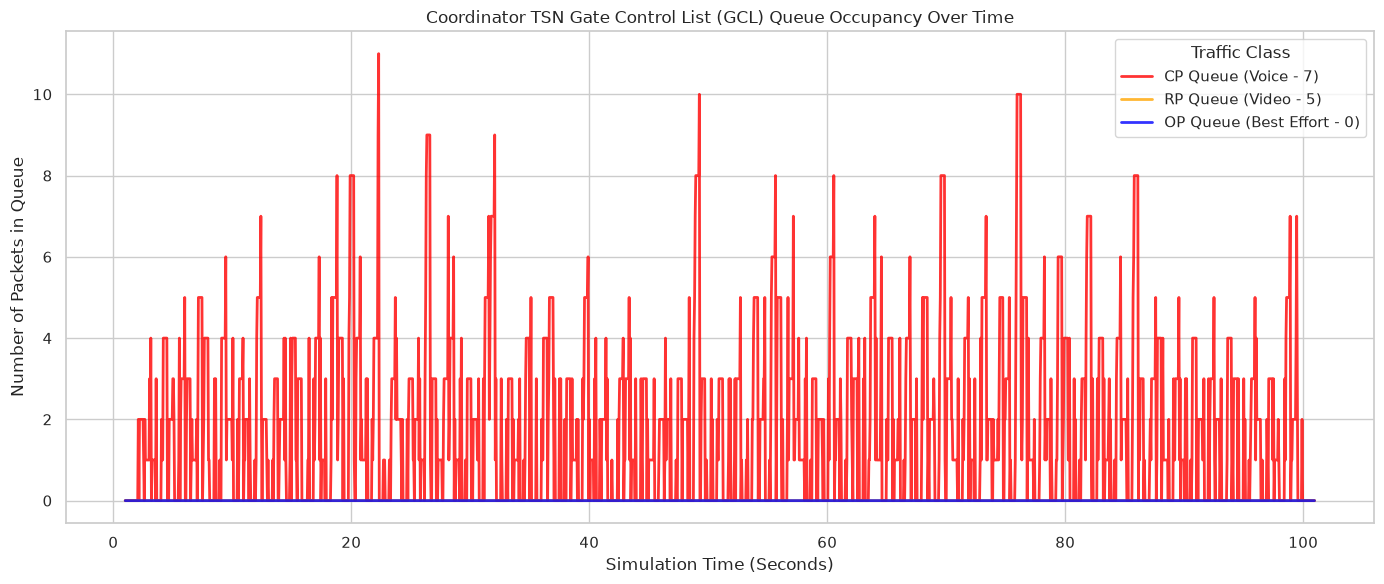

In [17]:
# =============================================================================
# 7. QUEUE OCCUPANCY VISUALIZATION
# =============================================================================
if not df_queues.empty:
    plt.figure(figsize=(14, 6))
    
    sns.lineplot(data=df_queues, x='Time_s', y='CP_Size', label='CP Queue (Voice - 7)', color='red', alpha=0.8, linewidth=2)
    sns.lineplot(data=df_queues, x='Time_s', y='RP_Size', label='RP Queue (Video - 5)', color='orange', alpha=0.8, linewidth=2)
    sns.lineplot(data=df_queues, x='Time_s', y='OP_Size', label='OP Queue (Best Effort - 0)', color='blue', alpha=0.8, linewidth=2)
    
    plt.title('Coordinator TSN Gate Control List (GCL) Queue Occupancy Over Time')
    plt.xlabel('Simulation Time (Seconds)')
    plt.ylabel('Number of Packets in Queue')
    plt.legend(title='Traffic Class')
    
    import matplotlib.ticker as ticker
    plt.gca().yaxis.set_major_locator(ticker.MaxNLocator(integer=True))
    
    plt.tight_layout()
    plt.show()
else:
    print("Queue telemetry data is not available or empty.")